In [2]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [3]:
from plotting_ts_tools import (
    calculate_anomaly,
    calculate_anomaly_timeslice,
    line_plot,
    line_plot_min_max,
    select_index,
    cleanup,
    adjust_names,
    adjust_length,
    line_plot_anomaly,
    box_plot_anomaly,
    lineplot_and_boxplot,
    load_era5_csv,
    load_rcms_csv
)

In [ ]:
# Select Variables
#
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#climate_index='R20mm' 
#climate_index= 'DD'
#climate_index= 'TG'
#cliamte_index='SU35'
#climate_index='SU40'
#climate_index='TR26'
climate_index='RRm'

var_meta = select_index(climate_index)
print(var_meta)
# select country and time step
#
#country='Togo'
country='Burkina Faso'
#country='Ivory Coast'
timestep='year'


{'longname': 'mean precipitation [mm/day]', 'unit_base': 'mm/day', 'description': 'Mean precipitation'}


In [158]:
# Load the CSV file containing the data for the selected index, country, and time step:
#
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+climate_index
file_name='climdexCORDEX_AFR22_'+climate_index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [159]:
# Load csv file for ERA5
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5/'+climate_index
file_name='climdexERA5_'+climate_index+'_'+timestep+'_weighted_means.csv'
era5_path = os.path.join(path,file_name)
era5data = pd.read_csv(era5_path)

In [160]:
var_meta

{'longname': 'mean precipitation [mm/day]',
 'unit_base': 'mm/day',
 'description': 'Mean precipitation'}

In [161]:
# define output path and filename
#
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/'+climate_index
#outfile = os.path.join(outputpath,climate_index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [162]:
# The data needs to be cut to the same length for all scenarios and the same time period for all indices.
# cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
# For TG, we need to load the data with longnameK to convert from K to °C in the load function. 
# For the other indices, we can load the data without longnameK.
#

if climate_index == 'TG':
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31', longnameK=var_meta['longnameK'])
else:
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31')

Loaded CORDEX AFR-22 data for country:  Ivory Coast  with index:  RRm
Data range:  1971-07-15 00:00:00  -  2098-07-15 00:00:00
Data columns:  Index(['realization', 'year', 'region', 'mean precipitation [mm/day]',
       'ci_name', 'ci_frequency', 'standard_name', 'units', 'GCM', 'RCM',
       'scenario'],
      dtype='object')
mean precipitation [mm/day]
Adjusted precipitation to mm/year for better comparison with Table. New longname:  Index(['realization', 'year', 'region', 'mean precipitation [mm/year]',
       'ci_name', 'ci_frequency', 'standard_name', 'units', 'GCM', 'RCM',
       'scenario'],
      dtype='object')


/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/TIMESERIES/plotting_ts_tools.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  'unit_base': 'days',


In [163]:
cut_data.head

<bound method NDFrame.head of                                               realization       year  \
1178    AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE... 1971-07-15   
1233    AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE... 1972-07-15   
1288    AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE... 1973-07-15   
1343    AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE... 1974-07-15   
1398    AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE... 1975-07-15   
...                                                   ...        ...   
135378  AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC... 2094-07-15   
135433  AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC... 2095-07-15   
135488  AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC... 2096-07-15   
135543  AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC... 2097-07-15   
135598  AFR-22_GERICS_ICTP-RegCM4-7-0ICTP-RegCM4-7_NCC... 2098-07-15   

             region  mean precipitation [mm/year] ci_name ci_frequency  \
1178    Ivory Coast            

In [164]:
# prepare era5 data
if climate_index == 'TG':
    era5_cut=load_era5_csv(era5_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', longnameK=var_meta['longnameK'])
else:
    era5_cut=load_era5_csv(era5_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', longnameK=var_meta['longname'])

In [165]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
if climate_index == "RRm":
    var_meta['longname'] = var_meta['longname'].replace('mm/day', 'mm/year')

print(var_meta['longname'])    
df_anomaly_year = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', var_meta['longname'])
#df.head()

mean precipitation [mm/year]


In [166]:
# Mean anomaly per time slice, for each realization and scenario
# Use pre-defined `slices` if available; otherwise fall back to standard ranges
slices_to_use = [
        ("2031-2060", 2031, 2060),
        ("2069-2098", 2069, 2098),
    ]
anom_slice_means = calculate_anomaly_timeslice(df_anomaly_year, slices_to_use)
anom_slice_means.head()

,slice,region,standard_name,realization,scenario,anomaly_mean,years
0,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp26,-11.095215,30
1,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp85,-49.506907,30
2,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp26,-85.311309,30
3,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp85,-142.221408,30
4,2031-2060,Ivory Coast,precipitation,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_NCC-NorESM...,rcp26,-243.239561,30


In [167]:
var_meta['longname']

'mean precipitation [mm/year]'

Saving figure to /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/RRm/RRm_Ivory_Coast_timeseries_box_minmax_p15p85.png


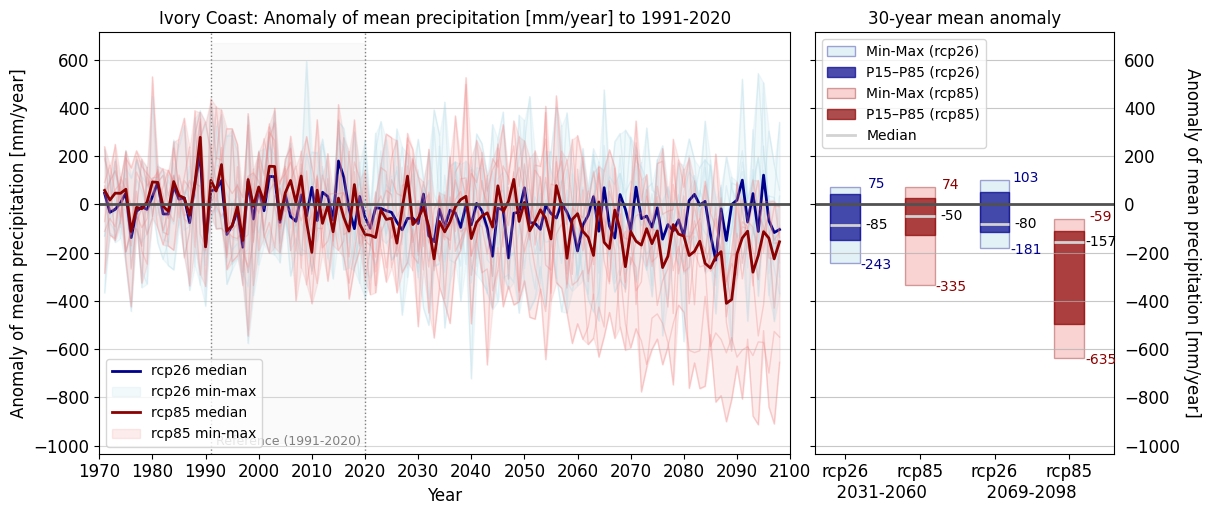

In [168]:
# now line plot with era5 and box plot beside each other in one figure:
# Increased label font sizes
#removed ERA5 for now outof the plotting function.
lineplot_and_boxplot(df_anomaly_year, df_era5_anomalie, 
                     anom_slice_means, country, climate_index, var_meta['longname'], outputpath)

test